# Actividad 5 (Evaluación) 
- Regresión lineal
- Regresion multiple
- Regresion logística

**Archivo de origen:** `Datos_Complementarios_CLV.xlsx`

## Objetivo de negocio
Analizar ventas e inventario para identificar variables asociadas con el importe neto de las ventas y construir un modelo de clasificación que identifique ventas de importe alto. El análisis es exploratorio: las asociaciones no son causalidad.

### Decisiones metodológicas
- **Regresión lineal simple y múltiple:** vamos a utilizar la sheet `Histórico_Ventas` y como variable dependiente `total_neto`, una variable cuantitativa.
- **Regresión logística:** se crea la variable binaria `venta_alta`, definida como una venta cuyo `total_neto` supera el percentil 75 del conjunto de entrenamiento. Así se evita escoger un umbral arbitrario y se obtiene una tarea de clasificación reproducible.
- `nombre_articulo` no se utiliza como variable dependiente lineal porque es texto/categoría, no una medida cuantitativa. Sí puede servir para agrupar o describir productos.
- `total_neto` suele estar relacionado por construcción con `precio_unitario × total_unidades`; por eso, un R² alto puede reflejar una relación contable, no necesariamente una capacidad predictiva generalizable. Se señala esta limitación en las conclusiones.

## 0. Preparar el entorno y cargar las tres hojas

In [13]:
#importamos librerias que utilizaremos mas adelante
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    ConfusionMatrixDisplay
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.utils import resample

#Ponemos la ruta en donde esta nuestro df
RUTA = "Datos_Complementarios_CLV.xlsx"

xls = pd.ExcelFile(RUTA)

#Revisamos cuantas hojas tiene nuestro df
print("Hojas disponibles:", xls.sheet_names)

#Generamos una variable x sheet para que sea mas sencillo el an
existencias = pd.read_excel(RUTA, sheet_name="Existencias_15_10_2026")
movimientos = pd.read_excel(RUTA, sheet_name="Histórico_Entradas_SAlidas")
ventas = pd.read_excel(RUTA, sheet_name="Histórico_Ventas")

# Normalizamos el df para darle presentacion
for df in [existencias, movimientos, ventas]:
    df.columns = df.columns.astype(str).str.strip()

# El nombre de una columna de ventas contiene espacios finales en el archivo original.
print("Existencias:", existencias.shape)
print("Movimientos:", movimientos.shape)
print("Ventas:", ventas.shape)
display(ventas.head())

Hojas disponibles: ['Existencias_15_10_2026', 'Histórico_Entradas_SAlidas', 'Histórico_Ventas']
Existencias: (2951, 6)
Movimientos: (55180, 7)
Ventas: (21632, 14)


,folio_abreviado,folio,fecha_documento,articulo_id,nombre_articulo,marc,precio_unitario,total_unidades,total_neto,nombre_cliente,estado,ciudad,cp,vendedor
0,B00,B00013159,15.10.2026,16301346,AIZIR 98 X 14mm OM1,AIDITE,1310.35000,1,1310.35,ARTURO HERNANDEZ SF,Estado de México,Estado de Mexico,55140.0,DIEGO
1,CDF,CDF002643,15.10.2026,7214,"LUMEX DENTINE, A1, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD
2,CDF,CDF002643,15.10.2026,7217,"LUMEX DENTINE, A2, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD
3,CDF,CDF002643,15.10.2026,7223,"LUMEX DENTINE, A3, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD
4,CDF,CDF002643,15.10.2026,7277,"LUMEX ENAMEL, CLEAR, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD


## 1. Mini sondeo de calidad de datos: tipos, duplicados y nulos

In [14]:
def resumen_calidad(df, nombre):
    print(f"\n--- {nombre} ---")
    print("Filas y columnas:", df.shape)

    #Generamos un mini df que nos de la info general de nuestro df
    display(pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "% nulos": (df.isna().mean() * 100).round(2),
        "valores únicos": df.nunique(dropna=True)
    }).sort_values("nulos", ascending=False))
    print("Filas duplicadas completas:", int(df.duplicated().sum()))

resumen_calidad(existencias, "Existencias")
resumen_calidad(movimientos, "Histórico de entradas/salidas")
resumen_calidad(ventas, "Histórico de ventas")


--- Existencias ---
Filas y columnas: (2951, 6)


,tipo,nulos,% nulos,valores únicos
articulo,int64,0,0.0,2951
nombre_articulo,str,0,0.0,2951
marca,str,0,0.0,26
almacen,str,0,0.0,1
existencias,int64,0,0.0,231
valor_inventario,float64,0,0.0,2016


Filas duplicadas completas: 0

--- Histórico de entradas/salidas ---
Filas y columnas: (55180, 7)


,tipo,nulos,% nulos,valores únicos
ANO,int64,0,0.0,7
MES,int64,0,0.0,12
SKU,object,0,0.0,5293
NOMBRE,str,0,0.0,5293
MARCA,str,0,0.0,40
SALIDAS,int64,0,0.0,271
ALMACEN,str,0,0.0,1


Filas duplicadas completas: 0

--- Histórico de ventas ---
Filas y columnas: (21632, 14)


,tipo,nulos,% nulos,valores únicos
cp,float64,492,2.27,1052
folio_abreviado,str,0,0.00,11
fecha_documento,str,0,0.00,204
articulo_id,int64,0,0.00,2130
nombre_articulo,str,0,0.00,2130
folio,str,0,0.00,5345
marc,str,0,0.00,25
precio_unitario,float64,0,0.00,2207
total_neto,float64,0,0.00,2652
total_unidades,int64,0,0.00,61


Filas duplicadas completas: 185


Existencias: no se encontraron valores nulos.
Movimientos: no se encontraron valores nulos.


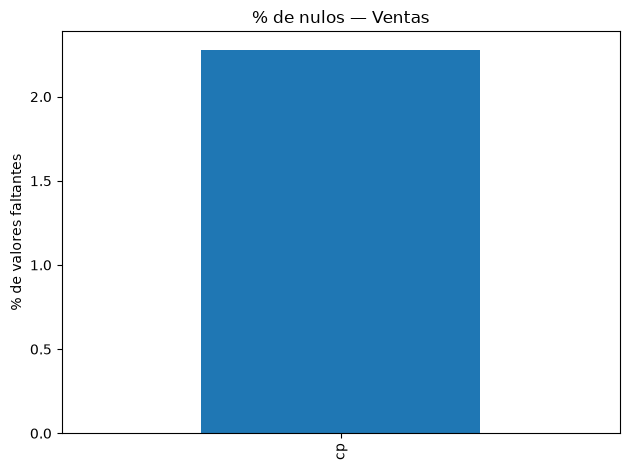

In [15]:
# Visualización de porcentaje de nulos por hoja
for nombre, df in {
    "Existencias": existencias,
    "Movimientos": movimientos,
    "Ventas": ventas
}.items():
    nulos = (df.isna().mean() * 100).sort_values(ascending=False)
    nulos = nulos[nulos > 0]
    if len(nulos):
        ax = nulos.plot(kind="bar", title=f"% de nulos — {nombre}", ylabel="% de valores faltantes")
        plt.tight_layout()
        plt.show()
    else:
        print(f"{nombre}: no se encontraron valores nulos.")

**MINI NOTA:** son muy pocos los nulos y me parece que es codigo postal entonces no creo que sea muy relevando eliminar toda la columna, podemos imputarlos con K-NN o como parte de la regresion

## 2. Preprocesamiento básico y diagnóstico de outliers

Se corrigen tipos de datos y se revisan valores atípicos con el rango intercuartílico (IQR). **No se eliminan automáticamente**: importes o cantidades altos pueden ser ventas legítimas. Para una decisión real, se investigan primero con el área de negocio.

In [16]:
# Convertir fecha a tipo datetime. Usaremos el formato día.mes.año.
ventas["fecha_documento"] = pd.to_datetime(
    ventas["fecha_documento"].astype(str),
    dayfirst=True,
    errors="coerce"
)
ventas["mes"] = ventas["fecha_documento"].dt.month
ventas["dia_semana"] = ventas["fecha_documento"].dt.dayofweek

# Nos aseguramos que las columnas numéricas en efecto sean numericas 
for col in ["precio_unitario", "total_unidades", "total_neto"]:
    ventas[col] = pd.to_numeric(ventas[col], errors="coerce")

# Revisión de valores negativos o ceros que podrían requerir validación
for col in ["precio_unitario", "total_unidades", "total_neto"]:
    print(f"{col}: negativos={(ventas[col] < 0).sum()}, ceros={(ventas[col] == 0).sum()}")

#Validamos transformaciones
display(ventas[["fecha_documento", "precio_unitario", "total_unidades", "total_neto"]].describe().T)

precio_unitario: negativos=0, ceros=1612
total_unidades: negativos=0, ceros=0
total_neto: negativos=0, ceros=1612


,count,mean,min,25%,50%,75%,max,std
fecha_documento,21632,2026-05-27 00:19:50.236686,2026-01-05 00:00:00,2026-03-25 00:00:00,2026-05-22 00:00:00,2026-08-05 00:00:00,2026-10-15 00:00:00,NaN
precio_unitario,21632.0,4337.611806,0.0,172.413793,614.689655,1284.48,2170948.2758,42838.116798
total_unidades,21632.0,2.792946,1.0,1.0,1.0,2.0,181.0,5.276435
total_neto,21632.0,5388.638264,0.0,200.0,948.28,2148.4975,2170948.28,43170.75037


,variable,Q1,Q3,IQR,límite inferior,límite superior,número de posibles outliers,% de posibles outliers
0,precio_unitario,172.413793,1284.4800,1112.066207,-1495.685518,2952.579311,1076,4.97
1,total_unidades,1.000000,2.0000,1.000000,-0.500000,3.500000,3659,16.91
2,total_neto,200.000000,2148.4975,1948.497500,-2722.746250,5071.243750,2150,9.94


C:\Users\Padfoot\AppData\Local\Temp\ipykernel_34436\2567460676.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(ventas[col].dropna(), vert=False)


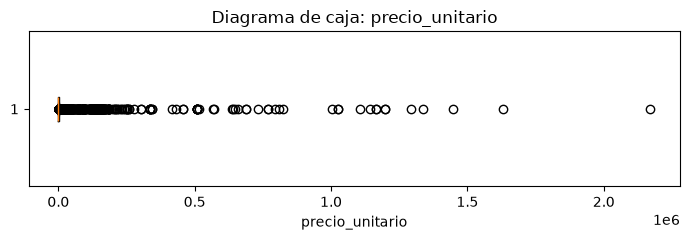

C:\Users\Padfoot\AppData\Local\Temp\ipykernel_34436\2567460676.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(ventas[col].dropna(), vert=False)


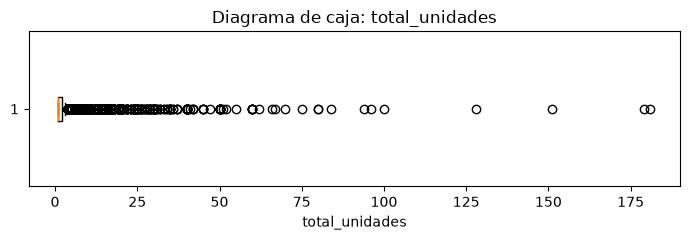

C:\Users\Padfoot\AppData\Local\Temp\ipykernel_34436\2567460676.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(ventas[col].dropna(), vert=False)


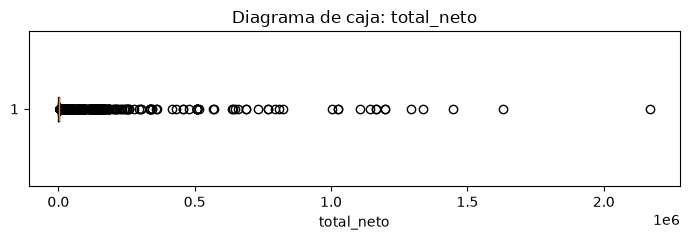

In [17]:
def tabla_outliers_iqr(df, columnas):
    filas = []
    for col in columnas:
        s = pd.to_numeric(df[col], errors="coerce").dropna()
        if s.empty:
            continue
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        inferior = q1 - 1.5 * iqr
        superior = q3 + 1.5 * iqr
        n = int(((s < inferior) | (s > superior)).sum())
        filas.append({
            "variable": col, "Q1": q1, "Q3": q3, "IQR": iqr,
            "límite inferior": inferior, "límite superior": superior,
            "número de posibles outliers": n,
            "% de posibles outliers": round(100*n/len(s), 2)
        })
    return pd.DataFrame(filas)

outliers_ventas = tabla_outliers_iqr(
    ventas, ["precio_unitario", "total_unidades", "total_neto"]
)
display(outliers_ventas)

# Boxplots para inspección visual
for col in ["precio_unitario", "total_unidades", "total_neto"]:
    plt.figure(figsize=(7, 2.5))
    plt.boxplot(ventas[col].dropna(), vert=False)
    plt.title(f"Diagrama de caja: {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

## 3. Regresión lineal simple

### Pregunta base de analisis
¿Cómo se relaciona una variable cuantitativa con el importe neto de una venta (`total_neto`)

Se identifica automáticamente la variable numérica con mayor correlación absoluta con `total_neto`, excluyendo la propia variable objetivo. La correlación mide asociación lineal, no causalidad. Como `precio_unitario`, `total_unidades` y `total_neto` pueden estar vinculados por cálculo, interpreta el resultado con esa precaución.

,precio_unitario,total_unidades,mes,dia_semana,total_neto
precio_unitario,1.000,-0.030,-0.002,-0.005,0.993
total_unidades,-0.030,1.000,-0.053,0.022,0.010
mes,-0.002,-0.053,1.000,-0.076,-0.003
dia_semana,-0.005,0.022,-0.076,1.000,-0.005
total_neto,0.993,0.010,-0.003,-0.005,1.000


Variable con mayor correlación absoluta con total_neto: precio_unitario
Correlación de Pearson: 0.9927


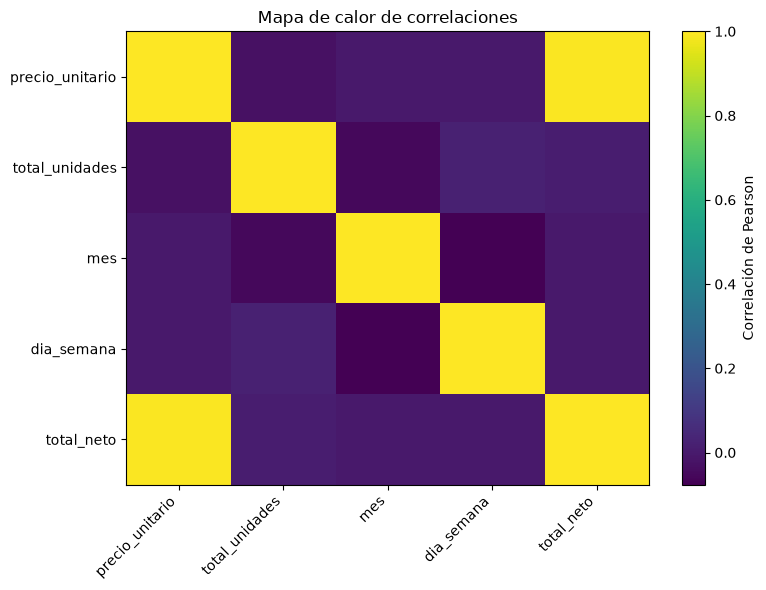

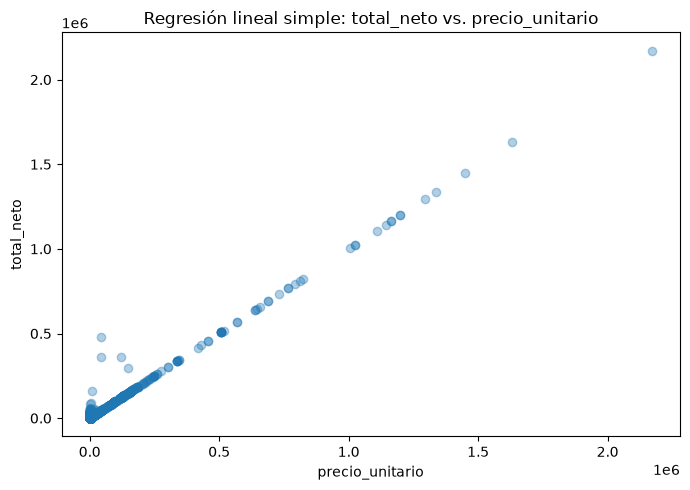

In [18]:
# Seleccionar variables cuantitativas y calcular correlaciones
num_cols = ventas.select_dtypes(include=np.number).columns.tolist()
# Excluir identificadores que son numéricos pero no cantidades con significado analítico
excluir = {"articulo_id", "cp"}
candidatas = [c for c in num_cols if c not in excluir and c != "total_neto"]

corr = ventas[candidatas + ["total_neto"]].corr(numeric_only=True)
display(corr.round(3))

correlaciones_objetivo = corr["total_neto"].drop("total_neto").dropna()
correlaciones_objetivo = correlaciones_objetivo.loc[
    correlaciones_objetivo.index.isin(candidatas)
]
variable_simple = correlaciones_objetivo.abs().idxmax()
print("Variable con mayor correlación absoluta con total_neto:", variable_simple)
print("Correlación de Pearson:", round(correlaciones_objetivo[variable_simple], 4))

# Heatmap usando matplotlib
plt.figure(figsize=(8, 6))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Correlación de Pearson")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Mapa de calor de correlaciones")
plt.tight_layout()
plt.show()

# Scatterplot
plt.figure(figsize=(7, 5))
plt.scatter(ventas[variable_simple], ventas["total_neto"], alpha=0.35)
plt.xlabel(variable_simple)
plt.ylabel("total_neto")
plt.title(f"Regresión lineal simple: total_neto vs. {variable_simple}")
plt.tight_layout()
plt.show()

Ecuación: total_neto = 1062.0294 + (1.0008 × precio_unitario)
R² entrenamiento: 0.9845
R² prueba: 0.9915
MAE prueba: 1463.42
RMSE prueba: 3189.58


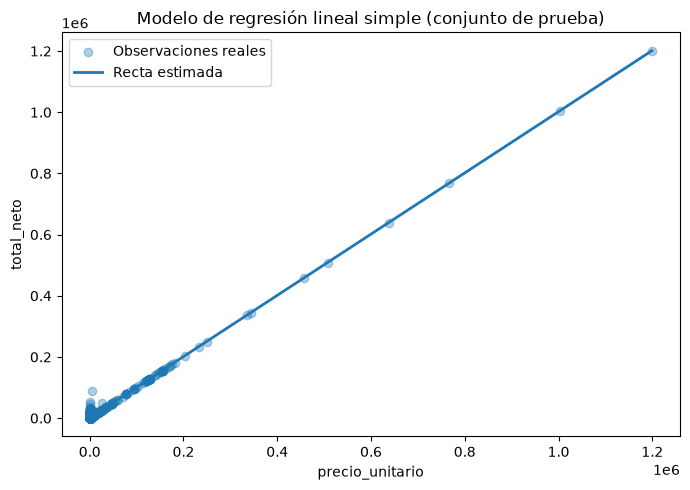

In [19]:
# Ajustar regresión simple con casos completos en ambas variables
datos_simple = ventas[[variable_simple, "total_neto"]].replace([np.inf, -np.inf], np.nan).dropna()
X_simple = datos_simple[[variable_simple]]
y_simple = datos_simple["total_neto"]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y_simple, test_size=0.2, random_state=42
)
modelo_simple = LinearRegression()
modelo_simple.fit(X_train_s, y_train_s)
pred_simple = modelo_simple.predict(X_test_s)

print(f"Ecuación: total_neto = {modelo_simple.intercept_:.4f} + "
      f"({modelo_simple.coef_[0]:.4f} × {variable_simple})")
print("R² entrenamiento:", round(modelo_simple.score(X_train_s, y_train_s), 4))
print("R² prueba:", round(r2_score(y_test_s, pred_simple), 4))
print("MAE prueba:", round(mean_absolute_error(y_test_s, pred_simple), 2))
print("RMSE prueba:", round(np.sqrt(mean_squared_error(y_test_s, pred_simple)), 2))

# Mostrar la recta ajustada sobre los datos de prueba
orden = np.argsort(X_test_s[variable_simple].to_numpy())
plt.figure(figsize=(7, 5))
plt.scatter(X_test_s[variable_simple], y_test_s, alpha=0.35, label="Observaciones reales")
plt.plot(X_test_s[variable_simple].to_numpy()[orden],
         pred_simple[orden], linewidth=2, label="Recta estimada")
plt.xlabel(variable_simple)
plt.ylabel("total_neto")
plt.title("Modelo de regresión lineal simple (conjunto de prueba)")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Regresión lineal múltiple

Se modela `total_neto` con variables cuantitativas de la transacción y algunas variables categóricas disponibles. Se excluyen identificadores, folios y nombres de clientes para evitar tratarlos como magnitudes o introducir información personal innecesaria. Se divide el conjunto en entrenamiento y prueba; los imputadores y la codificación se ajustan dentro del pipeline para evitar fuga de información.

In [20]:
# Preparar fecha y categorías
ventas["marca_modelo"] = ventas["marc"].fillna("SIN REGISTRO").astype(str)
ventas["estado_modelo"] = ventas["estado"].fillna("SIN REGISTRO").astype(str)
ventas["mes_modelo"] = ventas["mes"]

features_num = ["precio_unitario", "total_unidades", "mes_modelo"]
features_cat = ["marca_modelo", "estado_modelo"]
target = "total_neto"

datos_multi = ventas[features_num + features_cat + [target]].replace([np.inf, -np.inf], np.nan)
datos_multi = datos_multi.dropna(subset=[target])
X = datos_multi[features_num + features_cat]
y = datos_multi[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

preprocesador = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]), features_num),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), features_cat)
    ]
)

modelo_multi = Pipeline([
    ("preprocesamiento", preprocesador),
    ("regresion", LinearRegression())
])
modelo_multi.fit(X_train, y_train)
pred_multi = modelo_multi.predict(X_test)

r2_multi = r2_score(y_test, pred_multi)
mae_multi = mean_absolute_error(y_test, pred_multi)
rmse_multi = np.sqrt(mean_squared_error(y_test, pred_multi))

print("R² entrenamiento:", round(modelo_multi.score(X_train, y_train), 4))
print("R² prueba:", round(r2_multi, 4))
print("MAE prueba:", round(mae_multi, 2))
print("RMSE prueba:", round(rmse_multi, 2))

R² entrenamiento: 0.9864
R² prueba: 0.9938
MAE prueba: 1189.35
RMSE prueba: 2729.65


,variable,coeficiente
26,marca_modelo_VITA,-1061.674399
3,marca_modelo_AG,707.049044
4,marca_modelo_AIDITE,590.576712
30,estado_modelo_Baja California,561.989242
1,total_unidades,336.163670
59,estado_modelo_Puebla,-312.696541
38,estado_modelo_Ciudad de México,-207.458565
16,marca_modelo_HUGE,-153.526771
17,marca_modelo_IPD,-150.238887
37,estado_modelo_Chihuahua,143.404735


,modelo,R² prueba,MAE prueba,RMSE prueba
0,Lineal simple,0.991,1463.424,3189.579
1,Lineal múltiple,0.994,1189.350,2729.653


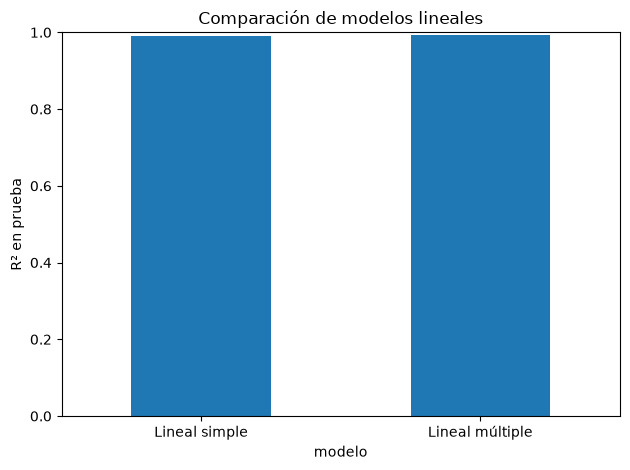

Mini Explicación: mayor R² y menores MAE/RMSE suelen indicar mejor ajuste en prueba,
pero también deben considerarse la fuga de información, los supuestos y el objetivo comercial.


In [21]:
# Extraer los nombres de variables transformadas y sus coeficientes
nombres_num = features_num
encoder = modelo_multi.named_steps["preprocesamiento"].named_transformers_["cat"].named_steps["onehot"]
nombres_cat = encoder.get_feature_names_out(features_cat).tolist()
nombres_features = nombres_num + nombres_cat
coeficientes = modelo_multi.named_steps["regresion"].coef_

tabla_coef = pd.DataFrame({
    "variable": nombres_features,
    "coeficiente": coeficientes
})
tabla_coef["abs_coeficiente"] = tabla_coef["coeficiente"].abs()
display(tabla_coef.sort_values("abs_coeficiente", ascending=False).drop(columns="abs_coeficiente").head(20))

# Comparación de métricas en conjunto de prueba
comparacion = pd.DataFrame([
    {"modelo": "Lineal simple", "R² prueba": r2_score(y_test_s, pred_simple),
     "MAE prueba": mean_absolute_error(y_test_s, pred_simple),
     "RMSE prueba": np.sqrt(mean_squared_error(y_test_s, pred_simple))},
    {"modelo": "Lineal múltiple", "R² prueba": r2_multi,
     "MAE prueba": mae_multi, "RMSE prueba": rmse_multi}
])
display(comparacion.round(3))

ax = comparacion.set_index("modelo")[["R² prueba"]].plot(kind="bar", legend=False, ylim=(0, 1))
ax.set_ylabel("R² en prueba")
ax.set_title("Comparación de modelos lineales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Mini Explicación: mayor R² y menores MAE/RMSE suelen indicar mejor ajuste en prueba,")
print("pero también deben considerarse la fuga de información, los supuestos y el objetivo comercial.")

## 5. Regresión logística

### Pregunta de negocio
¿Podemos clasificar una transacción como de **importe alto** o **importe no alto** con la información disponible?

La etiqueta `venta_alta` se define con el percentil 75 de `total_neto` del conjunto de entrenamiento; así se identifica el cuartil de ventas de mayor importe y se genera una clase minoritaria. La variable objetivo no se incluye como predictor. Para evitar que el sobremuestreo contamine la evaluación, primero se separan entrenamiento y prueba y **solo se sobremuestrea el entrenamiento**. Se usa sobremuestreo aleatorio de la clase minoritaria.

In [22]:
# Crear datos de modelado; el objetivo se define después de separar entrenamiento/prueba
features_log_num = ["precio_unitario", "total_unidades", "mes_modelo"]
features_log_cat = ["marca_modelo", "estado_modelo"]

datos_log = ventas[features_log_num + features_log_cat + ["total_neto"]].replace([np.inf, -np.inf], np.nan)
datos_log = datos_log.dropna(subset=["total_neto"]).copy()
X_log = datos_log[features_log_num + features_log_cat]
y_continuo = datos_log["total_neto"]

X_train_l, X_test_l, y_train_cont, y_test_cont = train_test_split(
    X_log, y_continuo, test_size=0.2, random_state=42
)

# El umbral (percentil 75) se calcula solo con el conjunto de entrenamiento
umbral_alto = y_train_cont.quantile(0.75)
y_train_l = (y_train_cont > umbral_alto).astype(int)
y_test_l = (y_test_cont > umbral_alto).astype(int)

print("Umbral para venta alta (percentil 75 del entrenamiento):", round(umbral_alto, 2))
print("Distribución original de clases en entrenamiento:")
display(y_train_l.value_counts().rename(index={0: "No alta", 1: "Alta"}).to_frame("cantidad"))
print("Distribución de clases en prueba:")
display(y_test_l.value_counts().rename(index={0: "No alta", 1: "Alta"}).to_frame("cantidad"))

Umbral para venta alta (percentil 75 del entrenamiento): 2155.18
Distribución original de clases en entrenamiento:


,cantidad
total_neto,
No alta,12980
Alta,4325


Distribución de clases en prueba:


,cantidad
total_neto,
No alta,3258
Alta,1069


In [23]:
# Imputar y codificar para poder aplicar el modelo logístico
pre_log = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), features_log_num),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), features_log_cat)
    ]
)

# Ajustar transformaciones únicamente con X_train; transformar train y test
X_train_t = pre_log.fit_transform(X_train_l)
X_test_t = pre_log.transform(X_test_l)

# Convertir a DataFrame para hacer sobremuestreo por clase
if hasattr(X_train_t, "toarray"):
    X_train_balance = X_train_t.toarray()
else:
    X_train_balance = np.asarray(X_train_t)

df_train_balance = pd.DataFrame(X_train_balance)
df_train_balance["objetivo"] = y_train_l.to_numpy()

clases = df_train_balance["objetivo"].value_counts()
clase_mayor = clases.idxmax()
clase_menor = clases.idxmin()

mayor = df_train_balance[df_train_balance["objetivo"] == clase_mayor]
menor = df_train_balance[df_train_balance["objetivo"] == clase_menor]

menor_sobremuestreada = resample(
    menor, replace=True, n_samples=len(mayor), random_state=42
)
train_balanceado = pd.concat([mayor, menor_sobremuestreada], axis=0).sample(
    frac=1, random_state=42
)

X_train_bal = train_balanceado.drop(columns="objetivo").to_numpy()
y_train_bal = train_balanceado["objetivo"].astype(int).to_numpy()

print("Antes del sobremuestreo:")
print(df_train_balance["objetivo"].value_counts().sort_index().to_dict())
print("Después del sobremuestreo:")
print(pd.Series(y_train_bal).value_counts().sort_index().to_dict())

Antes del sobremuestreo:
{0: 12980, 1: 4325}
Después del sobremuestreo:
{0: 12980, 1: 12980}


Accuracy: 0.9022
Precision: 0.732
Recall: 0.9532
F1: 0.8281
ROC-AUC: 0.9691

Reporte de clasificación:
              precision    recall  f1-score   support

     No alta       0.98      0.89      0.93      3258
        Alta       0.73      0.95      0.83      1069

    accuracy                           0.90      4327
   macro avg       0.86      0.92      0.88      4327
weighted avg       0.92      0.90      0.91      4327



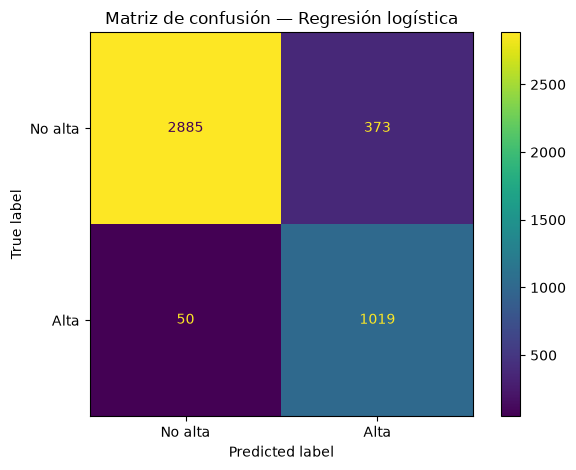

In [24]:
# Entrenar regresión logística
modelo_log = LogisticRegression(max_iter=2000, random_state=42)
modelo_log.fit(X_train_bal, y_train_bal)

pred_log = modelo_log.predict(X_test_t)
prob_log = modelo_log.predict_proba(X_test_t)[:, 1]

print("Accuracy:", round(accuracy_score(y_test_l, pred_log), 4))
print("Precision:", round(precision_score(y_test_l, pred_log, zero_division=0), 4))
print("Recall:", round(recall_score(y_test_l, pred_log, zero_division=0), 4))
print("F1:", round(f1_score(y_test_l, pred_log, zero_division=0), 4))
if len(np.unique(y_test_l)) == 2:
    print("ROC-AUC:", round(roc_auc_score(y_test_l, prob_log), 4))

print("\nReporte de clasificación:")
print(classification_report(y_test_l, pred_log, target_names=["No alta", "Alta"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test_l, pred_log, display_labels=["No alta", "Alta"], values_format="d"
)
plt.title("Matriz de confusión — Regresión logística")
plt.tight_layout()
plt.show()

## 6. Interpretación y conclusiones orientadas al socio formador

Completa estas conclusiones **después de ejecutar el notebook**. Sustituye los corchetes por los valores que aparezcan en las salidas; no inventes resultados.

1. **Calidad de datos.** En el archivo, la hoja `Histórico_Ventas` tiene faltantes o nulos en la columna`cp` con `492` valores y con `185` filas duplicadas. Los posibles outliers se detectaron en `precio_unitario, total_unidades y total_neto`. Deben analizarse o compararse entre ellos antes de eliminarlos porque pueden representar operaciones comerciales legítimas analizables.

2. **Regresión lineal simple.** La variable más correlacionada con `total_neto` fue `precio_unitario`, con correlación de Pearson de `0.9927`. El modelo obtuvo un R² de prueba de `0.9915`, un MAE de `1463.424` y un RMSE de `3189.579`. Esto indica que explica aproximadamente el `99.15%` de la variabilidad de `total_neto`. Estos resultados sugieren que el precio unitario es un **buen predictor** del total neto dentro de los datos analizados. Sin embargo, el error de predicción `(MAE = 1463.424 y RMSE = 3189.579)` indica que existen diferencias entre los valores reales y los estimados, especialmente en algunas observaciones.

3. **Regresión lineal múltiple.** El modelo múltiple obtuvo R² de prueba de `0.9938`, comparado con `0.9915` en el modelo simple. Como el error MAE/RMSE `disminuyó`, el modelo múltiple `mejoró` la predicción en datos no usados para entrenar.  Esto indica que explica aproximadamente el `99.38 %` de la variabilidad de total_neto. Además, el MAE disminuyó de **1463.424 a 1189.350** y el RMSE de **3189.579 a 2729.653**, lo que refleja una reducción en los errores de predicción. Estos resultados sugieren que la incorporación de múltiples variables predictoras permitió `mejorar el desempeño del modelo en los datos de prueba`, logrando predicciones más cercanas a los valores reales.

4. **Regresión logística.** La clasificación de venta alta obtuvo F1 de `0.8281`, recall de `0.9532` y ROC-AUC de `0.9691`. Para priorizar la detección de ventas altas, el recall mide qué proporción de las ventas realmente altas se identificó; la precisión mide qué proporción de las ventas marcadas como altas realmente lo eran.

5. **Implicación comercial.** Estos resultados pueden servir como análisis inicial para estudiar importes de venta, mezcla de productos y diferencias entre marcas/estados. Antes de usar el modelo para decisiones operativas, debe validarse en otro periodo y contrastarse con el proceso real de facturación.

6. **Limitaciones.** `total_neto` puede depender casi directamente de `precio_unitario` y `total_unidades`; por ello, un ajuste muy alto puede ser esperable y no prueba que el modelo descubra una relación causal. La variable `marca` o `estado` tampoco debe interpretarse como causa sin un diseño adecuado.